## Run SUMMA and MizuRoute ESP ##

Run the SUMMA and ESP models, with the model runs managed by Snakemake


### Write snakemake file ###

This block of code writes the snakemake file

In [3]:
config_file = "/Users/dcasson/GitHub/snow_dist/snakemake/config/chena_above_two_rivers.yaml"

In [229]:
%%writefile ../rules/run_summa_distributed.smk

from pathlib import Path
import sys
import pandas as pd
import pysumma as ps

sys.path.append('../scripts/')
import ss_utils

include: "../rules/run_pysumma_base.smk"
include: "../rules/merge_restart_files.smk"

rule run_summa_distributed:
    input:
        Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
        

Overwriting ../rules/run_summa_distributed.smk


In [12]:
! snakemake -s ../rules/run_pysumma_base.smk --cores 8 --configfile {config_file} --nolock

Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                         count
------------------------  -------
merge_summa_output_files        1
run_mizuroute                   1
run_pysumma_base                1
run_summa_in_gru_chunks        15
total                          18

Select jobs to execute...

[Tue Oct  8 20:26:02 2024]
rule run_summa_in_gru_chunks:
    input: /Users/dcasson/Data/yukon_esp/summa/settings/fileManager.txt
    output: /Users/dcasson/Data/yukon_esp/output/Chena_base_G10-12_timestep.nc
    log: logs/summa_Chena_base_G10-12.log
    jobid: 5
    reason: Missing output files: /Users/dcasson/Data/yukon_esp/output/Chena_base_G10-12_timestep.nc
    wildcards: gru_chunk=G10-12
    resources: tmpdir=/var/folders/w4/qfhdls_x5jj48jhgnhtfv1lm0000gn/T

[Tue Oct  8 20:26:02 2024]
rule run_summa_in_gru_chunks:
    input: /Users/dcasson/Data/yukon_esp/summa/settings/fileManager.txt
    output: 

In [8]:
%%writefile ../rules/run_pysumma_base.smk
"""
Snakemake file to run the base SUMMA simulations.

The model simulation is chunked by GRU to allow for parallelization on a cluster.

The chunks of GRUs are defined by the user.
"""

from pathlib import Path
import sys
import pandas as pd
import pysumma as ps

sys.path.append('../scripts/')
import ss_utils
import model_run_utils

# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration
output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
attributes_nc = Path(config['summa_settings_path'], config['attributes_nc'])
file_manager = Path(config['file_manager'])
summa_exe = Path(config['summa_exe'])
sim_start_time = config['model_start_time']
sim_end_time = config['model_end_time']
case_name = config['case_name']

# Read mizuroute configuration
mizuroute_exe = config['mizuroute_exe']
control_file_base = Path(config['mizuroute_settings_path'], config['mizuroute_control_file'])
ancil_dir = config['mizuroute_settings_path']

# Calculate the number of GRUs from the attributes_nc and generate chunk strings
num_grus = ss_utils.calc_num_grus(attributes_nc)
gru_chunks = ss_utils.generate_gru_start_and_count(
    num_grus, chunk_size=config['gru_chunk_size']
)

# Run the base SUMMA simulation
rule run_pysumma_base:
    input:
        Path(output_path, f"{config['case_name']}_{config['run_suffix']}_timestep.nc"),
        Path(output_path, f"{config['case_name']}_{config['run_suffix']}_routed.nc")

# Run SUMMA simulations for each GRU chunk
rule run_summa_in_gru_chunks:
    wildcard_constraints:
        gru_chunk='|'.join(gru_chunks)
    input:
        file_manager = file_manager
    output:
        summa_chunked_output = temp(Path(output_path, f"{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}_timestep.nc"))
    params:
        summa_exe = summa_exe,
        gru_start = lambda wildcards: ss_utils.extract_gru_int(wildcards.gru_chunk),
        gru_count = config['gru_chunk_size']
    log:
        log_file =  f"logs/summa_{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}.log"
    run:
        sim = ps.Simulation(params.summa_exe, input.file_manager)
        sim_config = {
            'manager': {
                'simStartTime': sim_start_time,
                'simEndTime': sim_end_time,
                'statePath': str(summa_restart_path) + '/',
                'outputPath': str(output_path) + '/'
            }
        }
        sim.apply_config(sim_config)

        if params.gru_start + params.gru_count > num_grus:
            params.gru_count = num_grus - params.gru_start + 1

        sim.run(
            run_suffix=config['run_suffix'],
            startGRU=params.gru_start,
            countGRU=params.gru_count,
            write_config=False,
            write_manager=True,
            freq_restart='m'
        )

        print(f"SUMMA simulation for GRUs {params.gru_start} to {params.gru_start + params.gru_count - 1} finished with {sim.status}.")

# Merge SUMMA output files
rule merge_summa_output_files:
    input:
        chunked_output_files = expand(
            Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}_timestep.nc"),
            gru_chunk=gru_chunks
        )
    output:
        merged_output_file = Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    run:
        print(f"Merging SUMMA output files into {output.merged_output_file}.")
        ss_utils.merge_netcdf_output(input.chunked_output_files, output.merged_output_file)
# Run MizuRoute
rule run_mizuroute:
    input:
        mizuroute_input = Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    output:
        mizuroute_output = Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_routed.nc")
    params:
        mizuroute_exe=mizuroute_exe,
        control_file_base=control_file_base,
        case_name=case_name,
        ancil_dir=ancil_dir,
        sim_start_time=sim_start_time,
        sim_end_time=sim_end_time,
        output_path=config['summa_output_path']
    run:
        #Set MizuRoute control file
        control_file_case = Path(output_path,f"{case_name}_mizuroute.control")
        #Set MizuRoute input file
        mizuroute_input = Path(input.mizuroute_input).name
        # Set timing
        start_time_pd = pd.to_datetime(params.sim_start_time)
        end_time_pd = pd.to_datetime(params.sim_end_time) - pd.Timedelta('1h')
        start_time_for_file_name=start_time_pd.strftime('%Y-%m-%d-%H')
        #Update control file
        model_run_utils.update_mizuroute_run_settings(
            params.control_file_base,
            control_file_case,
            mizuroute_input,
            params.case_name,
            start_time_pd,
            end_time_pd,
            params.ancil_dir,
            params.output_path,
            params.output_path
        )
        #Run MizuRoute
        model_run_utils.run_mizuroute(params.mizuroute_exe, control_file_case)
        #Rename output file
        generated_file = Path(params.output_path,f"{params.case_name}.h.{start_time_for_file_name}000.nc")
        generated_file.rename(output.mizuroute_output)

Overwriting ../rules/run_pysumma_base.smk


In [39]:
! snakemake -s ../rules/run_pysumma_base.smk --cores 8 --configfile {config_file} --nolock --forceall --notemp

Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                         count
------------------------  -------
merge_summa_output_files        1
run_mizuroute                   1
run_pysumma_base                1
run_summa_in_gru_chunks        15
total                          18

Select jobs to execute...

[Tue Oct  8 20:51:38 2024]
rule run_summa_in_gru_chunks:
    input: /Users/dcasson/Data/yukon_esp/summa/settings/fileManager.txt
    output: /Users/dcasson/Data/yukon_esp/output/Chena_base_G10-12_timestep.nc
    log: logs/summa_Chena_base_G10-12.log
    jobid: 5
    reason: Forced execution
    wildcards: gru_chunk=G10-12
    resources: tmpdir=/var/folders/w4/qfhdls_x5jj48jhgnhtfv1lm0000gn/T

[Tue Oct  8 20:51:38 2024]
rule run_summa_in_gru_chunks:
    input: /Users/dcasson/Data/yukon_esp/summa/settings/fileManager.txt
    output: /Users/dcasson/Data/yukon_esp/output/Chena_base_G16-18_timestep.nc
    l

In [40]:
%%writefile ../rules/merge_restart_files.smk
import os, sys
from pathlib import Path
from collections import defaultdict

# Directory containing the files
sys.path.append('../scripts/')
import ss_utils

# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration settings
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
filter_str = config['restart_file_filter']

# Get the files grouped by date
files_by_date = ss_utils.get_restart_files_by_date(summa_restart_path, filter_str)

# Create a list of dates (used as wildcards)
date_list = list(files_by_date.keys())
print(f"Date List: {date_list}")

rule all:
    input:
        expand(
            Path(summa_restart_path, f"{config['case_name']}_restart_{{date}}.nc"),
            date=date_list
        )

rule merge_restart_files_by_date:
    input:
        chunked_restart_files=lambda wildcards: files_by_date[wildcards.date]
    output:
        merged_output_file=Path(summa_restart_path, f"{config['case_name']}_restart_{{date}}.nc")
    wildcard_constraints:
        date=r"\d{10}"
    run:
        print(f"Merging restart files for date {wildcards.date}")
        print(f"Input files: {input.chunked_restart_files}")
        ss_utils.merge_netcdf_output(input.chunked_restart_files, output.merged_output_file)
        for file in input.chunked_restart_files:
            os.remove(file)

Overwriting ../rules/merge_restart_files.smk


In [41]:
! snakemake -s ../rules/merge_restart_files.smk --cores 8 --configfile {config_file} --nolock --forceall

Date List: ['2010120100', '2011010100', '2011040100', '2011080100', '2011050100', '2011090100', '2010100100', '2011060100', '2011030100', '2011070100', '2011020100', '2010110100']
Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                            count
---------------------------  -------
all                                1
merge_restart_files_by_date       12
total                             13

Select jobs to execute...

[Tue Oct  8 20:55:54 2024]
rule merge_restart_files_by_date:
    input: /Users/dcasson/Data/yukon_esp/output/restart_files/Chena_restart_2010120100_base_G22-24.nc, /Users/dcasson/Data/yukon_esp/output/restart_files/Chena_restart_2010120100_base_G16-18.nc, /Users/dcasson/Data/yukon_esp/output/restart_files/Chena_restart_2010120100_base_G19-21.nc, /Users/dcasson/Data/yukon_esp/output/restart_files/Chena_restart_2010120100_base_G43-44.nc, /Users/dcasson/Data/yukon_esp/output/resta

In [245]:
%%writefile ../scripts/run_initial_esp.smk

import os, sys
# Directory containing the files
sys.path.append('../scripts/')
import ss_utils
# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration settings
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
filter_str = config['restart_file_filter']
months = config['esp_months']

files_by_date = ss_utils.get_files_by_date(summa_restart_path, filter_str, months)
state_dates   = list(files_by_date.keys())
state_files   = list(files_by_date.values())

for state_date in state_dates:
    start_times, end_times = generate_times(state_date, start_year, stop_year, forecast_length)

run_suffixes ={}
output_paths = {}
for state_file, state_date in zip(state_files, state_dates):
    for start_time, end_time in zip(start_times, end_times):
        # Generate the run suffix
        start_year = pd.to_datetime(start_time).strftime("%Y")
        run_suffix = f"state{state_date}_year{start_year}"
        run_suffixes.append(run_suffix)
        # Generate the output path
        output_path = Path(config['summa_output_path'], f"{config['case_name']}_{run_suffix}")
        output_paths.append(output_path)

    
rule run_initial_esp:
    input: 
        expand(Path(output_path,f"{config['case_name']}_{config['run_suffix']}_timestep.nc"),
                output_path=output_paths)

rule prepare_esp_runs:
    output:
        summa_output = Path({output_path}, f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    params:
        summa_exe = config['summa_exe'],
        file_manager = Path(config['file_manager']),
        output_dir = {output_dir}
    run:
        sim = ps.Simulation(params.summa_exe, params.file_manager)

        sim_config = {
            'manager': {
                'simStartTime': {start_time},
                'simEndTime': {end_time},
                'initConditionFile': {state_file},
                'outputPath': {output_path}
            }
        }
        
        sim.apply_config(sim_config)

        sim.run(
            run_suffix=config['run_suffix'],
            write_config=True,
            write_manager=False,
        )


Overwriting ../scripts/run_initial_esp.smk


In [42]:
%%writefile ../scripts/run_esp.smk

import os
import sys
from pathlib import Path
import pandas as pd
import pysumma as ps
import logging

# Add the directory containing the helper scripts to the path
sys.path.append('../scripts/')
import ss_utils
import model_run_utils

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
my_logger = logging.getLogger(__name__)

# Promote config keys
config = ss_utils.promote_keys(config)

# Read in necessary configurations
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
summa_exe = config['summa_exe']
file_manager = Path(config['file_manager'])
filter_str = config['restart_file_filter']
months = config['esp_months']
start_year = int(config['esp_start_year'])
stop_year = int(config['esp_stop_year'])
forecast_length = int(config['forecast_length_days'])
case_name = config['case_name']
#summa_output_path = config['summa_output_path'].rstrip('/')
mizuroute_exe = config['mizuroute_exe']
control_file_base = Path(config['mizuroute_settings_path'], config['mizuroute_control_file'])
ancil_dir = config['mizuroute_settings_path']

# Get restart files by date
files_by_date = ss_utils.get_files_by_date(summa_restart_path, filter_str, months)
state_dates = list(files_by_date.keys())

# Generate list of start years
start_years = [str(year) for year in range(start_year, stop_year + 1)]
for state_date in state_dates:
    Path(summa_output_path, f"{case_name}/{state_date}").mkdir(parents=True, exist_ok=True)


rule run_esp:
    input:
        expand(f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc",
                state_date=state_dates,
                start_year=start_years),
        expand(f"{summa_output_path}/{case_name}/{{state_date}}/mizuroute_{{start_year}}.nc",
                state_date=state_dates,
                start_year=start_years)


# Rule to run SUMMA ensemble
rule run_summa_esp:
    output:
        summa_initial_output = f"{summa_output_path}/{case_name}_state{{state_date}}_year{{start_year}}/{case_name}_state{{state_date}}_year{{start_year}}_timestep.nc",
        summa_output = f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc"
    log:
        f"logs/summa_{{state_date}}_{{start_year}}.log"
    params:
        summa_exe=Path(summa_exe),
        file_manager=Path(file_manager),
        state_path = Path(summa_restart_path),
        state_date=lambda wildcards: pd.to_datetime(wildcards.state_date, format='%Y%m%d%H'),
        state_file=lambda wildcards: files_by_date[wildcards.state_date],
        start_year=lambda wildcards: wildcards.start_year,
        start_time=lambda wildcards: f"{wildcards.start_year}-{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%m-%d')}",
        end_time=lambda wildcards: (
            pd.to_datetime(f"{wildcards.start_year}-{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%m-%d')}") + pd.Timedelta(days=forecast_length)
        ).strftime("%Y-%m-%d"),
        output_path=lambda wildcards: Path(
            summa_output_path,
            f"{case_name}_state{wildcards.state_date}_year{wildcards.start_year}"
        )
    run:
        my_logger.info(f"Running SUMMA for state date: {wildcards.state_date}, year: {wildcards.start_year}")

        sim = ps.Simulation(params.summa_exe, params.file_manager)
        state = f"{case_name}_restart_{wildcards.state_date}.nc"
        my_logger.info(f"Using state file: {state}")

        sim_config = {
            'manager': {
                'simStartTime': params.start_time,
                'simEndTime': params.end_time,
                'statePath': str(params.state_path) + "/",
                'initConditionFile': state,
                'outputPath': str(params.output_path) + "/"
            }
        }

        sim.apply_config(sim_config)

        my_logger.info(f"Running SUMMA simulation with config: {sim_config}")
        sim.run(
            run_suffix=f"state{wildcards.state_date}_year{wildcards.start_year}",
            write_config=True,
            write_manager=False,
        )
        print(sim.status)

        # Shift time output, so ESP run starts at the state time.
        summa_output = f"{summa_output_path}/{case_name}_state{wildcards.state_date}_year{params.start_year}/{case_name}_state{wildcards.state_date}_year{params.start_year}_timestep.nc"
        summa_shifted_output = f"{summa_output_path}/{case_name}/{wildcards.state_date}/summa_{params.start_year}.nc"
        
        state_year_int = pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y')
        logger.info(f"Shifting SUMMA output time to {state_year_int}")
        
        model_run_utils.update_netcdf_time(summa_output, state_year_int, summa_shifted_output, file=True)

# Rule to run MizuRoute
rule run_mizuroute_esp:
    input:
        summa_output=f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc"
    output:
        mizuroute_output = f"{summa_output_path}/{case_name}/{{state_date}}/mizuroute_{{start_year}}.nc"
    log:
        f"logs/mizuroute_{{state_date}}_{{start_year}}.log"
    params:
        mizuroute_exe=mizuroute_exe,
        control_file_base=control_file_base,
        case_name=case_name,
        ancil_dir=ancil_dir,
        restart_path = summa_restart_path,
        start_year=lambda wildcards: wildcards.state_date[:4],
        start_time=lambda wildcards: f"{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y-%m-%d')}",
        end_time=lambda wildcards: (
            pd.to_datetime(f"{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y-%m-%d')}") + pd.Timedelta(days=forecast_length)
            -pd.Timedelta(hours=1)).strftime("%Y-%m-%d"),
        output_path=lambda wildcards: Path(summa_output_path,f"{case_name}/{wildcards.state_date}"),
        restart_file = f"{case_name}.r.{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y-%m-%d')}.nc"

    run:
        my_logger.info(f"Running MizuRoute for state date: {wildcards.state_date}, year: {wildcards.start_year}")

        mizuroute_input = Path(
            f"summa_{wildcards.start_year}.nc"
            #f"{case_name}_state{wildcards.state_date}_year{wildcards.start_year}_timestep.nc"
        )
        control_file_case = Path(
            f"{summa_output_path}/{case_name}_state{wildcards.state_date}_year{wildcards.start_year}",
            f"{case_name}_state{wildcards.state_date}_year{wildcards.start_year}.control"
        )
        start_time_pd = pd.to_datetime(params.start_time)
        end_time_pd = pd.to_datetime(params.end_time)

        my_logger.info(f"Updating MizuRoute control file: {control_file_case}")
update_mizuroute_run_settings(input_control_file,output_control_file, input_summa_file, case_name, sim_start, sim_end, ancil_dir, input_dir, output_dir):
        model_run_utils.update_mizuroute_run_settings(
            input_control_file=params.control_file_base,
            output_control_file=control_file_case,
            input_summa_file=mizuroute_input,
            case_name=params.case_name,
            sim_start=start_time_pd,
            sim_end=end_time_pd,
            ancil_dir=params.ancil_dir,
            input_dir=params.output_path,
            output_dir=Path(params.output_path,f'{wildcards.start_year}')
            restart_dir=params.restart_path
            restart_file=params.restart_file
        )
        Path(params.output_path,f'{wildcards.start_year}').mkdir(parents=True, exist_ok=True)
        my_logger.info(f"Running MizuRoute with input: {mizuroute_input}")

        #Run MizuRoute
        model_run_utils.run_mizuroute(params.mizuroute_exe, control_file_case)

        # Renaming the MizuRoute output file to meet expected naming convention
        generated_file = Path(params.output_path,f'{wildcards.start_year}', f"{params.case_name}.h.{params.start_time}-00000.nc")
        my_logger.info(f"Renaming file {generated_file} to {output.mizuroute_output}")
        generated_file.rename(output.mizuroute_output)

        #Path(params.output_path,f'{wildcards.start_year}').unlink()


Overwriting ../scripts/run_esp.smk


In [43]:
! snakemake -s ../scripts/run_esp.smk --cores 8 --configfile {config_file} --nolock --forceall

Building DAG of jobs...
2024-10-08 20:57:16,653 - WARNING - Building DAG of jobs...
Using shell: /bin/bash
2024-10-08 20:57:16,698 - WARNING - Using shell: /bin/bash
Provided cores: 8
2024-10-08 20:57:16,698 - WARNING - Provided cores: 8
Rules claiming more threads will be scaled down.
2024-10-08 20:57:16,698 - WARNING - Rules claiming more threads will be scaled down.
Job stats:
job                  count
-----------------  -------
run_esp                  1
run_mizuroute_esp       12
run_summa_esp           12
total                   25

2024-10-08 20:57:16,701 - WARNING - Job stats:
job                  count
-----------------  -------
run_esp                  1
run_mizuroute_esp       12
run_summa_esp           12
total                   25

Select jobs to execute...
2024-10-08 20:57:16,702 - WARNING - Select jobs to execute...

2024-10-08 20:57:16,705 - INFO - 
[Tue Oct  8 20:57:16 2024]
2024-10-08 20:57:16,705 - INFO - [Tue Oct  8 20:57:16 2024]
rule run_summa_esp:
    output: /U

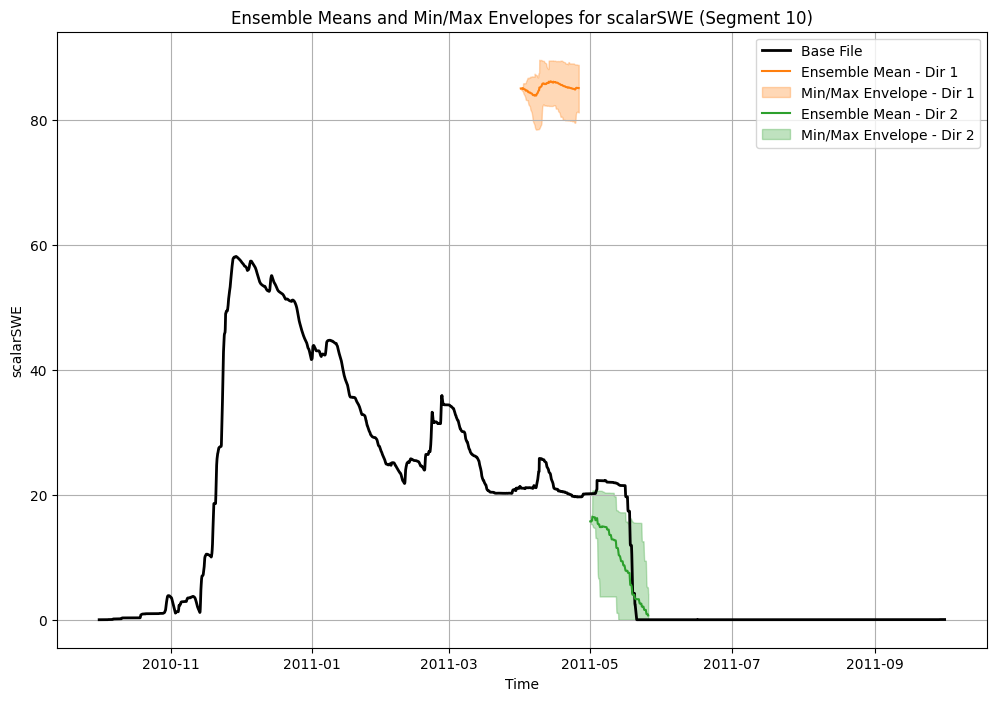

In [53]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import os

def plot_ensemble_from_directories(base_file, dir_list, file_pattern, variable="IRFroutedRunoff", seg_id=1):
    # Function to process files from a directory
    def load_ensemble_data(directory):
        ensemble_data = []
        for root, _, files in os.walk(directory):
            for file in files:
                if file_pattern in file:
                    file_path = os.path.join(root, file)
                    ds = xr.open_dataset(file_path)
                    if variable in ds:
                        try:
                            var_data = ds[variable].where(ds['hruId'] == seg_id, drop=True).squeeze()
                            ensemble_data.append(var_data)
                        except KeyError:
                            print(f"Segment ID '{seg_id}' not found in file {file_path}.")
                            continue
        return ensemble_data

    plt.figure(figsize=(12, 8))

    # Plot base file
    ds_base = xr.open_dataset(base_file)
    var_data_base = ds_base[variable].where(ds_base['hruId'] == seg_id, drop=True).squeeze()
    plt.plot(var_data_base['time'], var_data_base, label="Base File", color="black", linewidth=2)

    # Loop over each directory and process ensemble files
    for idx, directory in enumerate(dir_list):
        ensemble_data = load_ensemble_data(directory)

        if len(ensemble_data) > 0:
            # Stack ensemble data and calculate mean, max, and min across the ensemble dimension
            ensemble_stack = xr.concat(ensemble_data, dim="ensemble")
            ensemble_mean = ensemble_stack.mean(dim="ensemble").squeeze()
            ensemble_max = ensemble_stack.max(dim="ensemble").squeeze()
            ensemble_min = ensemble_stack.min(dim="ensemble").squeeze()
            color = f"C{idx+1}"  # Color cycling
            plt.plot(ensemble_mean['time'], ensemble_mean, label=f"Ensemble Mean - Dir {idx+1}", color=color)
            plt.fill_between(
                ensemble_mean['time'], ensemble_min, ensemble_max,
                color=color, alpha=0.3, label=f"Min/Max Envelope - Dir {idx+1}"
            )
        else:
            print(f"No files found in directory {directory} matching pattern '{file_pattern}'.")

    # Plot details
    plt.title(f'Ensemble Means and Min/Max Envelopes for {variable} (Segment {seg_id})')
    plt.xlabel('Time')
    plt.ylabel(variable)
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
base_file = '/Users/dcasson/Data/yukon_esp/output/Chena_base_timestep.nc'
dir_list = [
    '/Users/dcasson/Data/yukon_esp/output/Chena/2011040100',
    '/Users/dcasson/Data/yukon_esp/output/Chena/2011050100',
]  # Example directories
plot_ensemble_from_directories(base_file, dir_list, "summa", variable="scalarSWE", seg_id=24)

In [361]:
nc = '/Users/dcasson/Data/yukon_esp/summa/settings/Chena_restart_2010100100_base_G37-39.nc'

ds = xr.open_dataset(nc)
print(ds)
print(ds.hru)
print(ds.gru)

<xarray.Dataset> Size: 58kB
Dimensions:                    (scalarv: 1, hru: 11, spectral: 2, midToto: 13,
                                midSoil: 8, ifcToto: 14, tdh: 2000, gru: 3)
Dimensions without coordinates: scalarv, hru, spectral, midToto, midSoil,
                                ifcToto, tdh, gru
Data variables: (12/24)
    dt_init                    (scalarv, hru) float64 88B ...
    scalarCanopyIce            (scalarv, hru) float64 88B ...
    scalarCanopyLiq            (scalarv, hru) float64 88B ...
    scalarCanopyWat            (scalarv, hru) float64 88B ...
    scalarCanairTemp           (scalarv, hru) float64 88B ...
    scalarCanopyTemp           (scalarv, hru) float64 88B ...
    ...                         ...
    mLayerDepth                (midToto, hru) float64 1kB ...
    mLayerHeight               (midToto, hru) float64 1kB ...
    iLayerHeight               (ifcToto, hru) float64 1kB ...
    routingRunoffFuture        (tdh, gru) float64 48kB ...
    nSnow       